# 07 · When the combinatorial code appeared

Two views of how many odorants are read by more than one receptor.

1. **The first three stages.** S0 is node 0 (tree `node_1`), S1 the two class ancestors
   (nodes 1 and 2; `node_2`, `node_3`), S2 the three nodes below them (nodes 3, 4 and 5;
   `node_4`, `node_5`, `node_6`). For each, the odorants detected by at least one receptor,
   split into those read by exactly one and by two or more, at the model's default cut
   (median probability ≥ 0.5) and at the ASR density cut. Writes `results/stages.csv`.
2. **The trajectory** from node 0 to the 433 human receptors on the ultrametric time axis of
   `06`, with the measured M2OR values written over the extant rows (ancestral rows have no
   measurements). Writes `results/trajectory.csv` (Fig. 3g–i) and `results/checkpoints.csv`.
   `06` gives the same trajectory without the overlay, and `results/endpoint_overlay.csv`
   compares the two endpoints.

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))

from ancestral_sets import (ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE, CLASSES,
                            FIGURES, TABLES)

INPUTS = [ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE, CLASSES]
TABLES_WRITTEN = ["stages", "trajectory", "checkpoints"]
FIGURES_WRITTEN = ["stages"]

for path in INPUTS:
    print("input  ", os.path.relpath(path, REPO))
print("tables ", os.path.relpath(TABLES, REPO), TABLES_WRITTEN)
print("figures", os.path.relpath(FIGURES, REPO), FIGURES_WRITTEN)

input   Downstream_Analysis/predictions/aggregated/ASR_Predictions/asr_median_probability_wide.csv
input   Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv
input   Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv
input   Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa
input   Ancestral_Receptor_Reconstruction/human_tree_asr_hagfish_outgroup/PF13853_9606.7764.mafft.lg.treefile.rooted.withinternalnames
input   Phylogenetic_Analysis/data/HumanTree/human433_OR_classes.csv
tables  Downstream_Analysis/ancestral_receptors/results ['stages', 'trajectory', 'checkpoints']
figures Downstream_Analysis/ancestral_receptors/figures ['stages']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from plotting_functions import custom_plots, FIGSIZE
from ancestral_sets import (density_grid, overlay_grid, mpl_times, trajectory,
                            figure_node, save_fig, save_table)
plt.rcParams.update(custom_plots())

SINGLE_BAR, COMB_COL = "#c9c9c4", "#b08a3e"   # read by one receptor, by two or more

_, prob, fills, _ = density_grid()
ASR_CUT = fills["asr"].cut
print(f"ASR density cut {ASR_CUT:.4f}")

ASR density cut 0.8875


## The first three stages

     panel    cut stage                  nodes nodes_fig  n_receptors  encoded  labelled_line  combinatorial  pct_combinatorial
       raw 0.5000    S0                 node_1         0            1      177            177              0                0.0
       raw 0.5000    S1         node_2, node_3      1, 2            2      216            189             27               12.5
       raw 0.5000    S2 node_4, node_5, node_6   3, 4, 5            3      265            133            132               49.8
calibrated 0.8875    S0                 node_1         0            1       21             21              0                0.0
calibrated 0.8875    S1         node_2, node_3      1, 2            2       27             25              2                7.4
calibrated 0.8875    S2 node_4, node_5, node_6   3, 4, 5            3       53             36             17               32.1


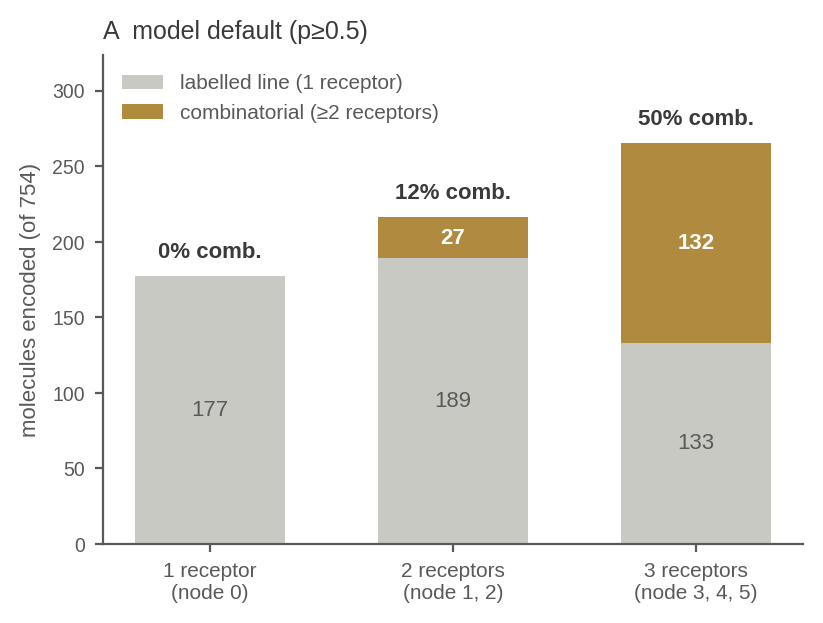

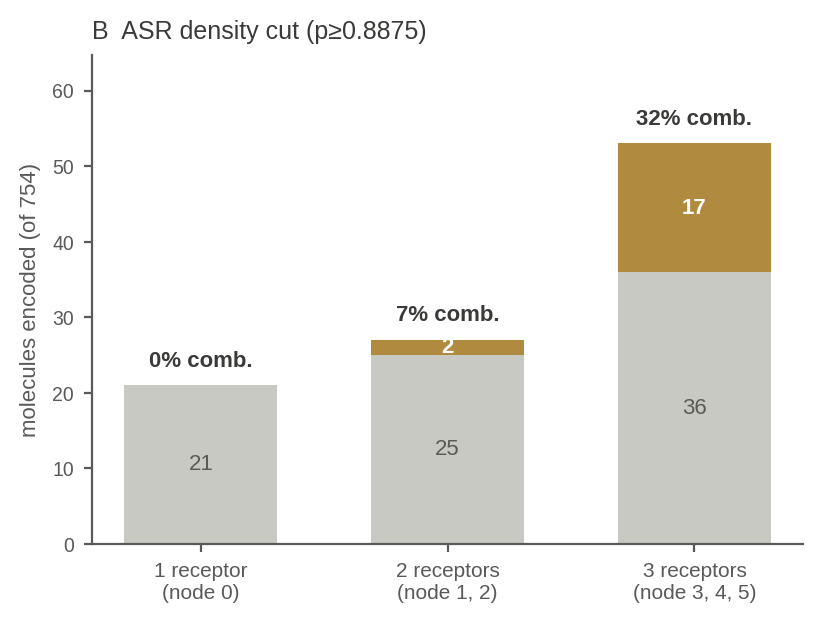

In [3]:
STAGES = {"S0": ["node_1"],
          "S1": ["node_2", "node_3"],
          "S2": ["node_4", "node_5", "node_6"]}


def stage_label(stage):
    nodes = ", ".join(str(figure_node(n)) for n in STAGES[stage])
    n = len(STAGES[stage])
    return f"{n} receptor{'s' if n > 1 else ''}\n(node {nodes})"


rows = []
for panel, cut in [("raw", 0.5), ("calibrated", ASR_CUT)]:
    for stage, nodes in STAGES.items():
        detectors = (prob.loc[nodes].values > cut).sum(axis=0)
        encoded = int((detectors > 0).sum())
        single = int((detectors == 1).sum())
        comb = int((detectors >= 2).sum())
        rows.append({"panel": panel, "cut": round(cut, 4), "stage": stage,
                     "nodes": ", ".join(nodes),
                     "nodes_fig": ", ".join(str(figure_node(n)) for n in nodes),
                     "n_receptors": len(nodes), "encoded": encoded,
                     "labelled_line": single, "combinatorial": comb,
                     "pct_combinatorial": round(100 * comb / encoded, 1) if encoded else 0.0})
stages = pd.DataFrame(rows)
save_table(stages, "stages")
print(stages.to_string(index=False))

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(2)])
for ax, (panel, title) in zip(axes, [("raw", "A  model default (p≥0.5)"),
                                     ("calibrated", f"B  ASR density cut (p≥{ASR_CUT:.4f})")]):
    block = stages[stages.panel == panel].set_index("stage").loc[list(STAGES)]
    x = np.arange(len(block))
    ax.bar(x, block.labelled_line, width=0.62, color=SINGLE_BAR, label="labelled line (1 receptor)")
    ax.bar(x, block.combinatorial, bottom=block.labelled_line, width=0.62,
           color=COMB_COL, label="combinatorial (≥2 receptors)")
    for i, r in enumerate(block.itertuples()):
        if r.labelled_line:
            # dark text: the grey bar is too light to carry white
            ax.text(i, r.labelled_line / 2, f"{r.labelled_line}", ha="center", va="center",
                    fontsize=8, color="#5a5a57")
        if r.combinatorial:
            ax.text(i, r.labelled_line + r.combinatorial / 2, f"{r.combinatorial}",
                    ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        ax.text(i, r.encoded + block.encoded.max() * 0.035, f"{r.pct_combinatorial:.0f}% comb.",
                ha="center", va="bottom", fontsize=8, fontweight="bold", color="#3a3a38")
    ax.set_xticks(x)
    ax.set_xticklabels([stage_label(s) for s in block.index], fontsize=7.5)
    ax.set_ylabel(f"molecules encoded (of {prob.shape[1]})")
    ax.set_ylim(0, block.encoded.max() * 1.22)
    ax.set_title(title, fontsize=9, loc="left", color="#3a3a38")
axes[0].legend(frameon=False, fontsize=7.5, loc="upper left")
save_fig(figures[0], "stages_raw"); save_fig(figures[1], "stages_calibrated"); plt.show()

## The trajectory with the experimental overlay

`overlay_grid()` fills the extant rows from their own scores with the measured cells held out,
then writes the measurements over them. The checkpoint table samples the trajectory at six
relative times.

In [4]:
overlaid, extant_fill, measured = overlay_grid()
print(f"{len(measured)} measured cells, {int(measured.sum())} positive")
print(f"ASR fill     cut {ASR_CUT:.4f}  density {fills['asr'].density:.4%}")
print(f"extant fill  cut {extant_fill.cut:.4f}  density {extant_fill.density:.4%}  (measurements written over)")

mpl = mpl_times()
traj = trajectory(mpl, binary=overlaid)
save_table(traj, "trajectory")

CHECKPOINTS = [0.0, 0.75, 0.83, 0.90, 0.96, 1.0]
check = trajectory(mpl, grid=np.array(CHECKPOINTS), binary=overlaid)


def receptors(row):
    # at t = 0 the only lineage is node_1, which belongs to neither class clade
    if row.n_class_I or row.n_class_II:
        return f"{int(row.n_class_I)} + {int(row.n_class_II)}"
    return str(int(row.n_lineages))


table = pd.DataFrame({
    "relative time": [f"{t:g}" for t in check.t],
    "receptors (Class I + Class II)": [receptors(r) for r in check.itertuples()],
    "odorants detected": check.n_detected.astype(int).values,
    "single detector": check.n_single.astype(int).values,
    "combinatorial (>=2)": check.n_combinatorial.astype(int).values,
    "Class I only / both / Class II only": [
        "–" if not (r.only_I or r.both or r.only_II)
        else f"{int(r.only_I)} / {int(r.both)} / {int(r.only_II)}"
        for r in check.itertuples()],
}).set_index("relative time").T
save_table(table.reset_index(), "checkpoints")
table

23782 measured cells, 1128 positive
ASR fill     cut 0.8875  density 2.2623%
extant fill  cut 0.8917  density 2.7453%  (measurements written over)


relative time,0,0.75,0.83,0.9,0.96,1
receptors (Class I + Class II),1,26 + 112,37 + 184,54 + 250,56 + 310,62 + 371
odorants detected,21,549,650,660,666,687
single detector,21,109,101,93,95,61
combinatorial (>=2),0,440,549,567,571,626
Class I only / both / Class II only,–,28 / 233 / 288,38 / 283 / 329,37 / 340 / 283,33 / 344 / 289,17 / 370 / 300


In [5]:
last = traj.iloc[-1]
print(f"endpoint: {int(last.n_class_I)} + {int(last.n_class_II)} receptors, "
      f"{int(last.n_detected)} odorants detected ({int(last.only_I)} class I only, "
      f"{int(last.both)} both, {int(last.only_II)} class II only), "
      f"{int(last.n_combinatorial)} combinatorial, {int(last.n_single)} single detector")

endpoint: 62 + 371 receptors, 687 odorants detected (17 class I only, 370 both, 300 class II only), 626 combinatorial, 61 single detector
